In [1]:
# IMPORTAR LIBRERÍAS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Scikit-learn: Machine Learning
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Configuración de reproducibilidad y estilos
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print("Librerías importadas correctamente.")
print(f"  - pandas: {pd.__version__}")
print(f"  - numpy: {np.__version__}")
print(f"  - scikit-learn: {__import__('sklearn').__version__}")

Librerías importadas correctamente.
  - pandas: 2.2.3
  - numpy: 2.1.3
  - scikit-learn: 1.6.1


In [3]:
# CARGAR EL DATASET LIMPIO
df_raw = pd.read_csv('dataset_limpio_Smart_Campus.csv')

# Convertir la columna fecha a formato datetime
df_raw['fecha'] = pd.to_datetime(df_raw['fecha'])

# Agrupar a nivel diario para analizar la demanda global del Smart Campus
df = df_raw.groupby('fecha').agg(
    estudiantes_presentes=('estudiantes_presentes', 'sum'),
    horas_uso_promedio=('horas_uso', 'mean'),
    porcentaje_ocupacion_medio=('porcentaje_ocupacion', 'mean')
).reset_index()

In [4]:
# Ordenar cronológicamente por seguridad
df = df.sort_values('fecha').reset_index(drop=True)

# Extraer características temporales básicas
df['dia_semana'] = df['fecha'].dt.dayofweek
df['mes'] = df['fecha'].dt.month

print(f"Dataset diario agrupado: {df.shape[0]} registros, {df.shape[1]} columnas.")
print(df.head())

Dataset diario agrupado: 181 registros, 6 columnas.
       fecha  estudiantes_presentes  horas_uso_promedio  \
0 2026-01-15                    784            2.305556   
1 2026-01-16                    982            2.437500   
2 2026-01-17                   1321            2.327273   
3 2026-01-18                    862            2.295455   
4 2026-01-19                   1378            2.363636   

   porcentaje_ocupacion_medio  dia_semana  mes  
0                   70.569722           3    1  
1                   65.573542           4    1  
2                   76.559091           5    1  
3                   60.762273           6    1  
4                   66.655152           0    1  


In [5]:
# VERIFICAR NULOS Y ESTADÍSTICAS
print("INFORMACIÓN DEL DATASET DIARIO:")
print("=" * 50)
print(df.info())

print("\nVALORES NULOS:")
print(df.isnull().sum())

print(f"\nRANGO TEMPORAL:")
print(f"  Desde: {df['fecha'].min().strftime('%Y-%m-%d')}")
print(f"  Hasta: {df['fecha'].max().strftime('%Y-%m-%d')}")

print("\nESTADÍSTICAS DE ESTUDIANTES PRESENTES:")
print(df['estudiantes_presentes'].describe().to_string())

INFORMACIÓN DEL DATASET DIARIO:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 181 entries, 0 to 180
Data columns (total 6 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   fecha                       181 non-null    datetime64[ns]
 1   estudiantes_presentes       181 non-null    int64         
 2   horas_uso_promedio          181 non-null    float64       
 3   porcentaje_ocupacion_medio  181 non-null    float64       
 4   dia_semana                  181 non-null    int32         
 5   mes                         181 non-null    int32         
dtypes: datetime64[ns](1), float64(2), int32(2), int64(1)
memory usage: 7.2 KB
None

VALORES NULOS:
fecha                         0
estudiantes_presentes         0
horas_uso_promedio            0
porcentaje_ocupacion_medio    0
dia_semana                    0
mes                           0
dtype: int64

RANGO TEMPORAL:
  Desde: 2026-01-15
  Hasta: 2

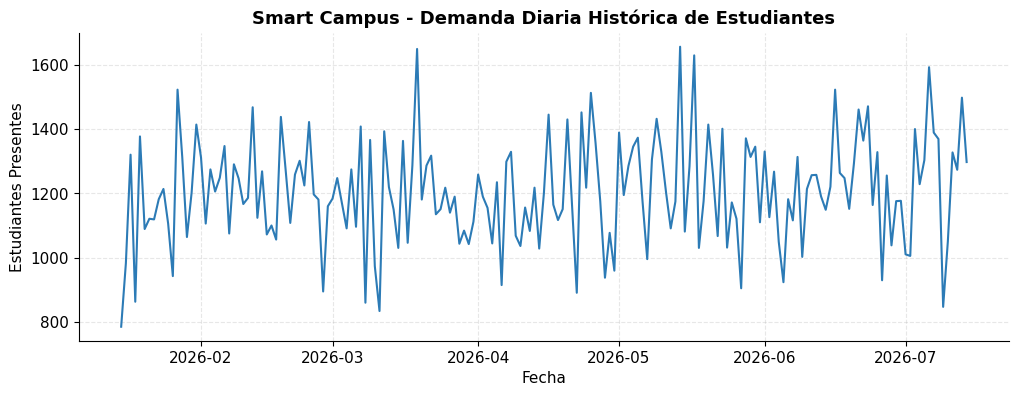

In [6]:
# Gráfico de la serie histórica
plt.figure(figsize=(12, 4))
plt.plot(df['fecha'], df['estudiantes_presentes'], color='#2c7bb6', linewidth=1.5)
plt.title('Smart Campus - Demanda Diaria Histórica de Estudiantes', fontsize=13, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Estudiantes Presentes')
plt.grid(True, alpha=0.3, linestyle='--')
plt.show()

In [7]:
# CREAR VARIABLES DE REZAGO Y MEDIA MÓVIL DESFASADA
df['lag_1'] = df['estudiantes_presentes'].shift(1)
df['lag_7'] = df['estudiantes_presentes'].shift(7)

# Corrección: Primero shift(1) para desplazar el pasado, luego rolling y mean
df['media_movil_7'] = (
    df['estudiantes_presentes']
    .shift(1)
    .rolling(window=7)
    .mean()
)

# Eliminar filas con valores nulos generados por el rezago inicial
df_modelo = df.dropna().copy()

print(f"Dimensiones después de crear lags y eliminar nulos: {df_modelo.shape}")
print(df_modelo.head())

Dimensiones después de crear lags y eliminar nulos: (174, 9)
        fecha  estudiantes_presentes  horas_uso_promedio  \
7  2026-01-22                   1119            2.294118   
8  2026-01-23                   1182            2.534483   
9  2026-01-24                   1214            2.339623   
10 2026-01-25                   1106            2.360000   
11 2026-01-26                    942            2.466667   

    porcentaje_ocupacion_medio  dia_semana  mes   lag_1   lag_7  media_movil_7  
7                    69.024118           3    1  1121.0   784.0    1076.714286  
8                    65.138103           4    1  1119.0   982.0    1124.571429  
9                    74.350189           5    1  1182.0  1321.0    1153.142857  
10                   72.233000           6    1  1214.0   862.0    1137.857143  
11                   66.991111           0    1  1106.0  1378.0    1172.714286  


In [8]:
# SELECCIONAR FEATURES Y TARGET
features = [
    'dia_semana',
    'mes',
    'lag_1',
    'lag_7',
    'media_movil_7'
]

X = df_modelo[features]
y = df_modelo['estudiantes_presentes']

print("Variables predictoras (X) seleccionadas:", features)
print(f"Dimensiones de X: {X.shape} | Dimensiones de y: {y.shape}")

Variables predictoras (X) seleccionadas: ['dia_semana', 'mes', 'lag_1', 'lag_7', 'media_movil_7']
Dimensiones de X: (174, 5) | Dimensiones de y: (174,)


In [9]:
# DIVISIÓN CRONOLÓGICA
corte = int(len(df_modelo) * 0.80)

X_train = X.iloc[:corte]
X_test = X.iloc[corte:]
y_train = y.iloc[:corte]
y_test = y.iloc[corte:]
fecha_test = df_modelo['fecha'].iloc[corte:]

print(f"Conjunto de Entrenamiento: {X_train.shape[0]} registros")
print(f"Conjunto de Prueba:        {X_test.shape[0]} registros\n")

# Verificación de rangos de fecha
print("--- VERIFICACIÓN DE CORTE CRONOLÓGICO ---")
print("Última fecha de entrenamiento:", df_modelo['fecha'].iloc[corte - 1].strftime('%Y-%m-%d'))
print("Primera fecha de prueba:       ", df_modelo['fecha'].iloc[corte].strftime('%Y-%m-%d'))
print("Última fecha de prueba:       ", df_modelo['fecha'].iloc[-1].strftime('%Y-%m-%d'))

Conjunto de Entrenamiento: 139 registros
Conjunto de Prueba:        35 registros

--- VERIFICACIÓN DE CORTE CRONOLÓGICO ---
Última fecha de entrenamiento: 2026-06-09
Primera fecha de prueba:        2026-06-10
Última fecha de prueba:        2026-07-14


In [10]:
# ENTRENAR BASELINE
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
pred_baseline = baseline.predict(X_test)

# Métricas del Baseline
mae_base = mean_absolute_error(y_test, pred_baseline)
rmse_base = mean_squared_error(y_test, pred_baseline) ** 0.5
r2_base = r2_score(y_test, pred_baseline)

print("--- MÉTRICAS DEL BASELINE ---")
print(f"Baseline MAE:  {mae_base:.2f}")
print(f"Baseline RMSE: {rmse_base:.2f}")
print(f"Baseline R Cuadrado:   {r2_base:.4f}")

--- MÉTRICAS DEL BASELINE ---
Baseline MAE:  135.86
Baseline RMSE: 172.09
Baseline R Cuadrado:   -0.0878


In [11]:
# ENTRENAR REGRESIÓN LINEAL
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Predicciones sobre el conjunto de prueba
pred = modelo.predict(X_test)

# Métricas del modelo
mae = mean_absolute_error(y_test, pred)
rmse = mean_squared_error(y_test, pred) ** 0.5
r2 = r2_score(y_test, pred)

print("--- MÉTRICAS DEL MODELO (Regresión Lineal) ---")
print(f"Modelo MAE:  {mae:.2f}")
print(f"Modelo RMSE: {rmse:.2f}")
print(f"Modelo R²:   {r2:.4f}")

--- MÉTRICAS DEL MODELO (Regresión Lineal) ---
Modelo MAE:  142.74
Modelo RMSE: 181.20
Modelo R²:   -0.2060


In [12]:
# TABLA COMPARATIVA
comparacion = pd.DataFrame({
    "Modelo": ["Baseline (Media)", "Regresión Lineal"],
    "MAE": [mae_base, mae],
    "RMSE": [rmse_base, rmse],
    "R2": [r2_base, r2]
})

print(comparacion.to_string(index=False))

# Mejora porcentual del MAE frente al baseline
mejora_mae = ((mae_base - mae) / mae_base) * 100
print(f"\nMejora porcentual del MAE frente al baseline: {mejora_mae:.2f}%")

          Modelo        MAE       RMSE        R2
Baseline (Media) 135.857348 172.093928 -0.087839
Regresión Lineal 142.735892 181.203089 -0.206048

Mejora porcentual del MAE frente al baseline: -5.06%


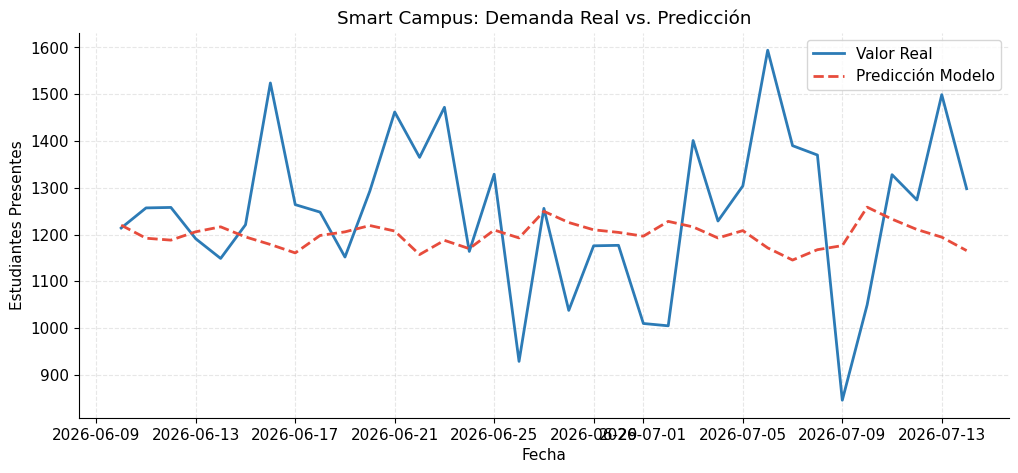

In [16]:
# Grafico 1: Serie temporal Real vs Predicción en prueba
plt.figure(figsize=(12, 5))
plt.plot(fecha_test, y_test.values, label="Valor Real", color='#2c7bb6', linewidth=2)
plt.plot(fecha_test, pred, label="Predicción Modelo", color='#e74c3c', linestyle='--', linewidth=2)
plt.title("Smart Campus: Demanda Real vs. Predicción")
plt.xlabel("Fecha")
plt.ylabel("Estudiantes Presentes")
plt.legend()
plt.grid(True, alpha=0.3, linestyle='--')
plt.show()



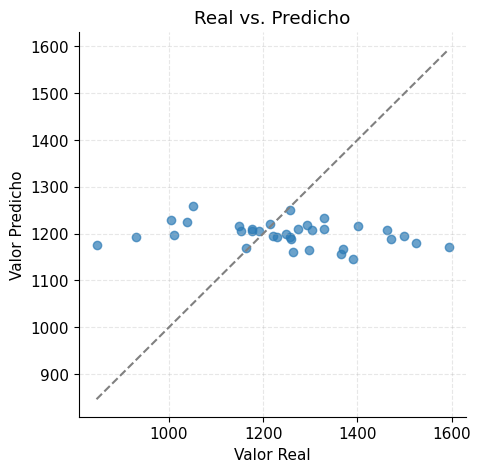

In [15]:
# Grafico 2: Dispersión Real vs Predicho
plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred, alpha=0.7, color='#2c7bb6')
lim_min = min(y_test.min(), pred.min())
lim_max = max(y_test.max(), pred.max())
plt.plot([lim_min, lim_max], [lim_min, lim_max], color='gray', linestyle='--')
plt.xlabel("Valor Real")
plt.ylabel("Valor Predicho")
plt.title("Real vs. Predicho")
plt.grid(True, alpha=0.3, linestyle='--')
plt.show()

In [18]:
# ANÁLISIS DE RESIDUOS, ERRORES Y COEFICIENTES
resultados = pd.DataFrame({
    "fecha": fecha_test.values,
    "real": y_test.values,
    "prediccion": pred,
    "baseline": pred_baseline
})

resultados["residuo"] = resultados["real"] - resultados["prediccion"]
resultados["error_abs"] = resultados["residuo"].abs()

# Añadir el día de la semana (0 = Lunes, 6 = Domingo)
resultados["dia_semana"] = pd.to_datetime(resultados["fecha"]).dt.dayofweek

print("TOP 5 DE MAYORES ERRORES ABSOLUTOS:")
print(resultados.nlargest(5, "error_abs")[["fecha", "dia_semana", "real", "prediccion", "error_abs"]].to_string(index=False))

# REVISAR COEFICIENTES DEL MODELO
coeficientes = pd.DataFrame({
    "variable": features,
    "coeficiente": modelo.coef_
}).sort_values("coeficiente", key=abs, ascending=False)

print("\nCOEFICIENTES DEL MODELO:")
print(coeficientes.to_string(index=False))

TOP 5 DE MAYORES ERRORES ABSOLUTOS:
     fecha  dia_semana  real  prediccion  error_abs
2026-07-06           0  1594 1171.560790 422.439210
2026-06-16           1  1524 1178.816070 345.183930
2026-07-09           3   846 1176.421971 330.421971
2026-07-13           0  1499 1194.526740 304.473260
2026-06-23           1  1472 1187.696719 284.303281

COEFICIENTES DEL MODELO:
     variable  coeficiente
   dia_semana     5.844343
          mes     0.354084
        lag_1    -0.113301
        lag_7     0.043769
media_movil_7     0.016180


In [20]:
# GUARDAR EVIDENCIAS Y SALIDAS
resultados.to_csv("predicciones_guia08.csv", index=False, encoding="utf-8")
comparacion.to_csv("metricas_guia08.csv", index=False, encoding="utf-8")

print("Archivos exportados exitosamente:")
print("  - predicciones_guia08.csv")
print("  - metricas_guia08.csv")

from google.colab import files
files.download("predicciones_guia08.csv")
files.download("metricas_guia08.csv")

Archivos exportados exitosamente:
  - predicciones_guia08.csv
  - metricas_guia08.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>